In [24]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve()
if not (project_root / "dataset" / "Maths.csv").exists():
    project_root = project_root.parent
data_path = project_root / "dataset" / "Maths.csv"
try:
    df = pd.read_csv(data_path)
except (UnicodeDecodeError, ValueError, pd.errors.ParserError):
    df = pd.read_excel(data_path)

df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Dataset inspection

In [25]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
df.describe()

Shape: (397, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      397 non-null    str  
 1   sex         397 non-null    str  
 2   age         397 non-null    int64
 3   address     397 non-null    str  
 4   famsize     397 non-null    str  
 5   Pstatus     397 non-null    str  
 6   Medu        397 non-null    int64
 7   Fedu        397 non-null    int64
 8   Mjob        397 non-null    str  
 9   Fjob        397 non-null    str  
 10  reason      397 non-null    str  
 11  guardian    397 non-null    str  
 12  

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000
mean,16.705290,2.748111,2.521411,1.450882,2.032746,0.335013,3.944584,3.234257,3.108312,1.478589,2.289673,3.556675,5.695214,10.881612,10.687657,10.377834
std,1.279716,1.097301,1.090672,0.696840,0.838731,0.742714,0.894400,0.996476,1.112762,0.889143,1.286770,1.388967,7.988015,3.333120,3.770322,4.604928
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Detect outliers using IQR

In [26]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Calculate Q1 and Q3
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Detect outliers
outliers = ((df[numeric_cols] < lower_bound) |
            (df[numeric_cols] > upper_bound))

# Count outliers per column
print(outliers.sum().sort_values(ascending=False))

failures      84
studytime     27
famrel        26
freetime      19
Dalc          18
absences      15
G2            13
traveltime     8
Fedu           2
age            1
Medu           0
goout          0
health         0
Walc           0
G1             0
G3             0
dtype: int64


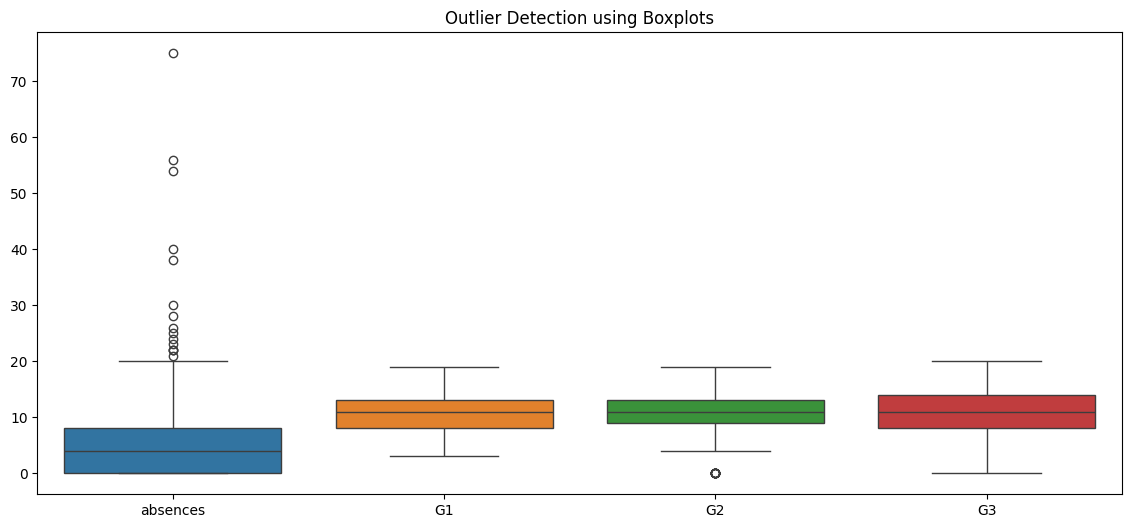

In [27]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[['absences', 'G1', 'G2', 'G3']])

plt.title("Outlier Detection using Boxplots")
plt.show()

In [28]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation
corr_matrix = numeric_df.corr()

# Display correlation with target G3
print(corr_matrix['G3'].sort_values(ascending=False))

G3            1.000000
G2            0.905238
G1            0.802676
Medu          0.220783
Fedu          0.155256
studytime     0.104015
famrel        0.050468
absences      0.037944
freetime      0.013131
Dalc         -0.049826
Walc         -0.052185
health       -0.065737
traveltime   -0.122475
goout        -0.127760
age          -0.172175
failures     -0.361237
Name: G3, dtype: float64


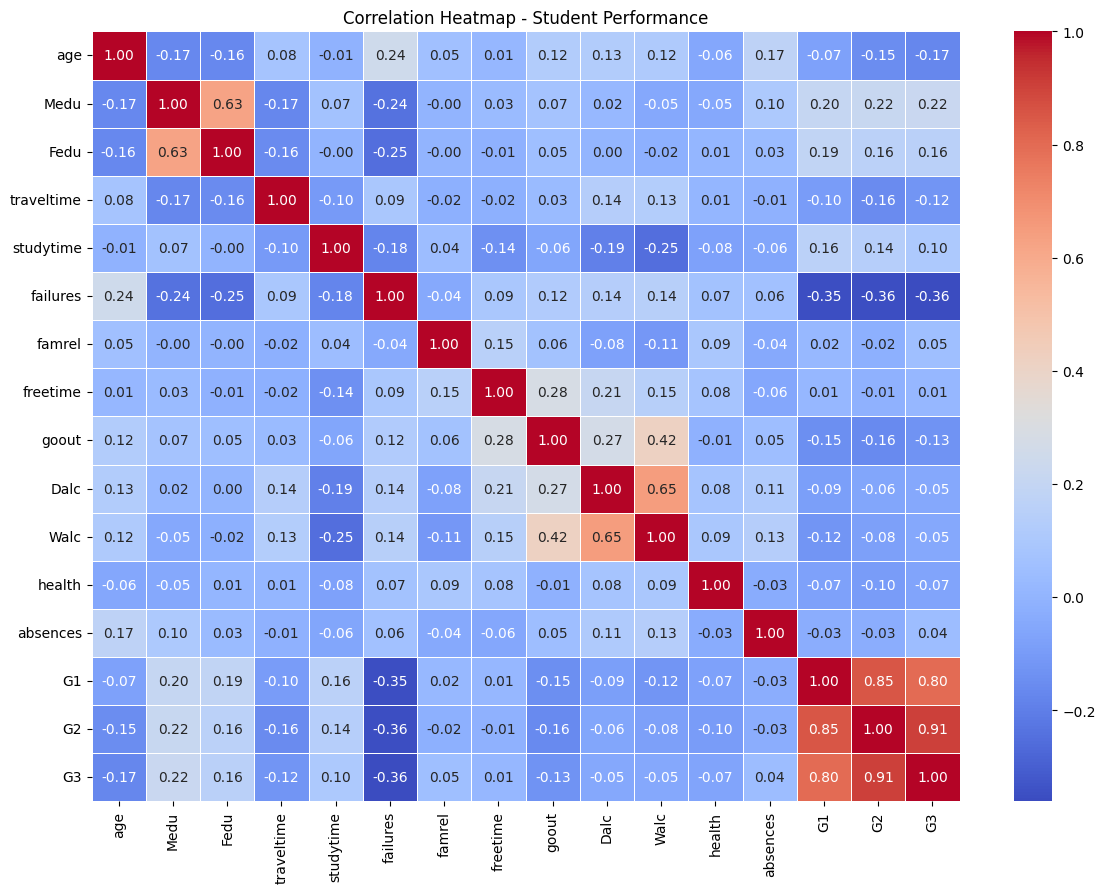

In [29]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap - Student Performance")
plt.show()

In [30]:
# Correlation with target
target_corr = corr_matrix['G3'].drop('G3')

# Sort by absolute correlation
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

print(target_corr)

G2            0.905238
G1            0.802676
failures     -0.361237
Medu          0.220783
age          -0.172175
Fedu          0.155256
goout        -0.127760
traveltime   -0.122475
studytime     0.104015
health       -0.065737
Walc         -0.052185
famrel        0.050468
Dalc         -0.049826
absences      0.037944
freetime      0.013131
Name: G3, dtype: float64


In [31]:
# Input features
X = df.select_dtypes(include=np.number).drop(columns=['G3'])

# Target variable
y = df['G3']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

Features shape: (397, 15)
Target shape: (397,)

Selected Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [32]:
from sklearn.model_selection import train_test_split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (317, 15)
X_test: (80, 15)
y_train: (317,)
y_test: (80,)


In [34]:
from sklearn.linear_model import LinearRegression

# Create model
model = LinearRegression()

In [35]:
# Train model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [36]:
# Predict on test data
y_pred = model.predict(X_test)

print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred[:10])

Actual values: [ 9  8 12 15  5 11 14 10  0 10]
Predicted values: [ 9.28673134  6.72187111 12.97237965 15.21401434  5.03594198 11.20143566
 12.33268636  7.17490675 -2.64113278  8.93513682]


In [37]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [38]:
# R2 Score
r2 = r2_score(y_test, y_pred)

# MAE
mae = mean_absolute_error(y_test, y_pred)

# RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model Evaluation Results")
print("------------------------")
print("R2 Score:", round(r2, 4))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

Model Evaluation Results
------------------------
R2 Score: 0.8681
MAE: 1.0615
RMSE: 1.6299


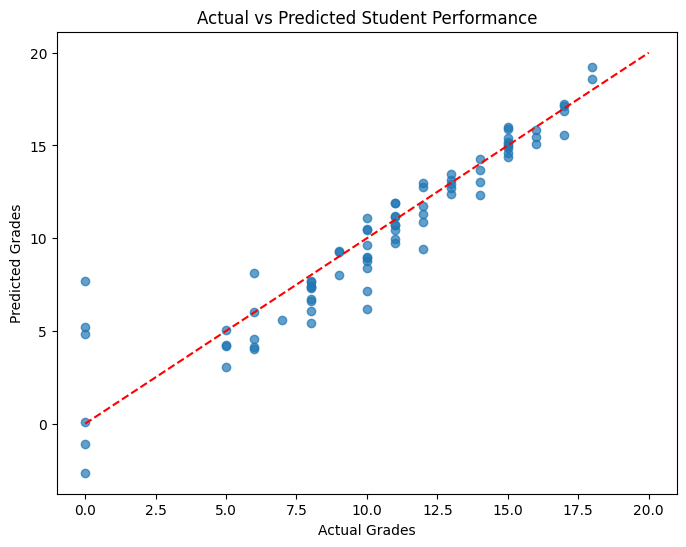

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [0, 20],
    [0, 20],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Student Performance")

plt.show()

In [40]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison['Error'] = comparison['Actual'] - comparison['Predicted']

print(comparison.head(15))

    Actual  Predicted     Error
0        9   9.286731 -0.286731
1        8   6.721871  1.278129
2       12  12.972380 -0.972380
3       15  15.214014 -0.214014
4        5   5.035942 -0.035942
5       11  11.201436 -0.201436
6       14  12.332686  1.667314
7       10   7.174907  2.825093
8        0  -2.641133  2.641133
9       10   8.935137  1.064863
10      15  15.381751 -0.381751
11       8   7.423026  0.576974
12      17  17.219592 -0.219592
13      15  14.993263  0.006737
14      11  11.900997 -0.900997


In [41]:
# Display model coefficients

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

print("Intercept:", model.intercept_)
print(coefficients)


Intercept: 1.0858183609379548
       Feature  Coefficient
14          G2     0.977730
6       famrel     0.249668
13          G1     0.166502
3   traveltime     0.153559
1         Medu     0.087259
8        goout     0.080933
11      health     0.073748
10        Walc     0.059092
12    absences     0.044975
7     freetime     0.005497
9         Dalc    -0.048672
4    studytime    -0.080879
2         Fedu    -0.085300
5     failures    -0.289813
0          age    -0.289957


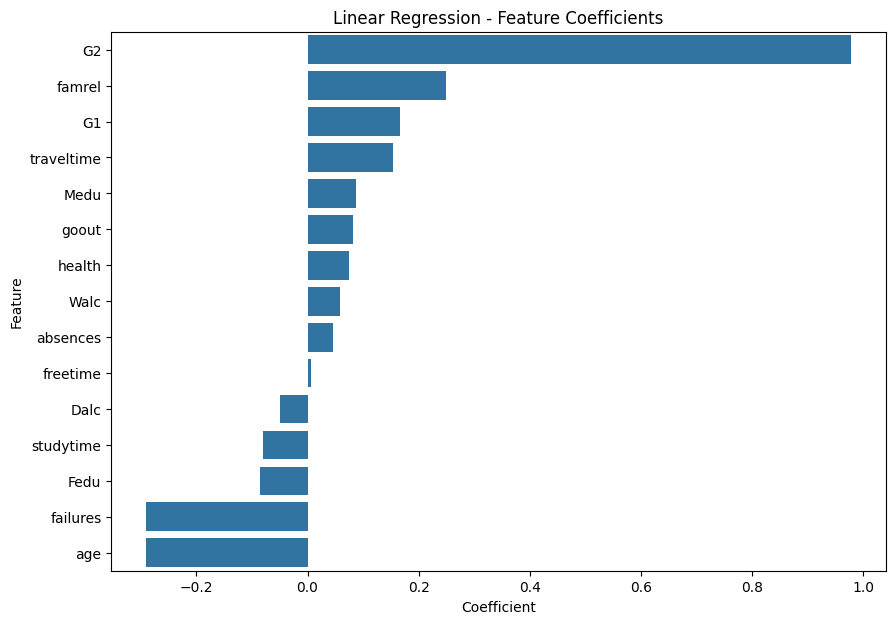

In [42]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=coefficients,
    x='Coefficient',
    y='Feature'
)

plt.title("Linear Regression - Feature Coefficients")
plt.show()

# Build Model 2

In [44]:
# Remove G1 and G2
X2 = df.select_dtypes(include=np.number).drop(
    columns=['G1', 'G2', 'G3']
)

# Target
y2 = df['G3']

print("New features shape:", X2.shape)
print("Target shape:", y2.shape)

New features shape: (397, 13)
Target shape: (397,)


In [45]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.2,
    random_state=42
)

In [46]:
model2 = LinearRegression()

model2.fit(X2_train, y2_train)

print("Model 2 training completed!")

Model 2 training completed!


In [47]:
y2_pred = model2.predict(X2_test)

In [48]:
r2_2 = r2_score(y2_test, y2_pred)

mae_2 = mean_absolute_error(y2_test, y2_pred)

rmse_2 = np.sqrt(mean_squared_error(y2_test, y2_pred))

print("Model 2 Evaluation")
print("------------------")
print("R2 Score:", round(r2_2, 4))
print("MAE:", round(mae_2, 4))
print("RMSE:", round(rmse_2, 4))

Model 2 Evaluation
------------------
R2 Score: 0.1132
MAE: 3.3023
RMSE: 4.2268


In [49]:
comparison = pd.DataFrame({
    'Metric': ['R2 Score', 'MAE', 'RMSE'],
    'Model 1 (All Features)': [r2, mae, rmse],
    'Model 2 (Without G1/G2)': [r2_2, mae_2, rmse_2]
})

print(comparison)

     Metric  Model 1 (All Features)  Model 2 (Without G1/G2)
0  R2 Score                0.868136                 0.113201
1       MAE                1.061536                 3.302293
2      RMSE                1.629893                 4.226765


In [50]:
final_results = pd.DataFrame({
    'Model': [
        'Linear Regression (With G1, G2)',
        'Linear Regression (Without G1, G2)'
    ],
    'R2 Score': [r2, r2_2],
    'MAE': [mae, mae_2],
    'RMSE': [rmse, rmse_2]
})

print(final_results.round(4))

                                Model  R2 Score     MAE    RMSE
0     Linear Regression (With G1, G2)    0.8681  1.0615  1.6299
1  Linear Regression (Without G1, G2)    0.1132  3.3023  4.2268


In [51]:
final_results.to_csv(
    'model_comparison.csv',
    index=False
)

# Project Conclusion – Student Performance Prediction

In this project, Exploratory Data Analysis and Machine Learning techniques were applied to the Student Performance dataset containing 397 student records.

The analysis included missing-value inspection, statistical summaries, outlier detection using the IQR method, correlation analysis, and feature selection.

Two Multiple Linear Regression models were developed using Scikit-learn.

**Model 1 – With Previous Grades:**
- R² Score: 0.8681
- MAE: 1.0615
- RMSE: 1.6299

**Model 2 – Without Previous Grades:**
- R² Score: 0.1132
- MAE: 3.3023
- RMSE: 4.2268

The first model demonstrated substantially better predictive performance. The experiment highlighted the strong predictive relationship between previous examination grades (G1 and G2) and final grades (G3).

The project provided practical experience in data preprocessing, exploratory data analysis, feature selection, regression modelling, prediction, and model evaluation.

**Conclusion:** Previous academic performance is a particularly valuable predictor of final mathematics grades in this dataset.